In [24]:
#  Imports
import json
import sys
import pandas as pd

#  Load all hyperparameter tuning results for DenseNet121
with open("densenet_cv_all_results.json", "r") as f:
    all_results = json.load(f)

#  Convert to DataFrame for sorting and display
df_results = pd.DataFrame(all_results)

#  Sort by descending accuracy
df_sorted = df_results.sort_values(by="accuracy", ascending=False).reset_index(drop=True)

#  Display all hyperparameter tuning results
print(" All Hyperparameter Tuning Results (DenseNet121):\n")
display(df_sorted)

#  Best configuration
best_config = df_sorted.iloc[0].to_dict()

#  Show best configuration
print("\n Best Hyperparameter Configuration for DenseNet121:")
print(json.dumps(best_config, indent=4))


 All Hyperparameter Tuning Results (DenseNet121):



,learning_rate,weight_decay,accuracy,precision,recall,f1_score,parameters_million
0,0.0003,0.00010,99.05,99.03,99.03,99.03,6.96
1,0.0001,0.00001,98.98,98.94,98.94,98.94,6.96
2,0.0001,0.00010,98.74,98.71,98.71,98.71,6.96
3,0.0003,0.00001,98.56,98.52,98.54,98.53,6.96



 Best Hyperparameter Configuration for DenseNet121:
{
    "learning_rate": 0.0003,
    "weight_decay": 0.0001,
    "accuracy": 99.05,
    "precision": 99.03,
    "recall": 99.03,
    "f1_score": 99.03,
    "parameters_million": 6.96
}


Using device: cuda

Epoch 1/5


→ Train Accuracy: 91.49%

Epoch 2/5


→ Train Accuracy: 96.31%

Epoch 3/5


→ Train Accuracy: 97.20%

Epoch 4/5


→ Train Accuracy: 98.23%

Epoch 5/5


→ Train Accuracy: 97.27%



🢾 Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.96      0.98       300
  meningioma       0.95      0.96      0.95       306
     notumor       0.99      0.99      0.99       405
   pituitary       0.96      0.98      0.97       300

    accuracy                           0.97      1311
   macro avg       0.97      0.97      0.97      1311
weighted avg       0.97      0.97      0.97      1311



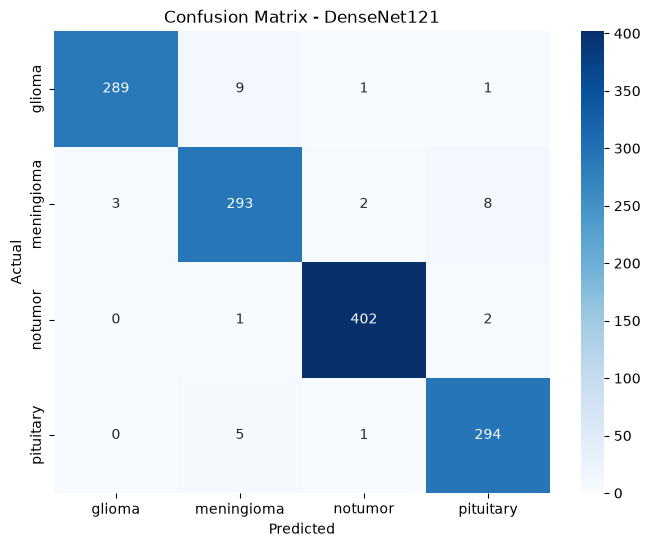

In [25]:
#  Final Training + Testing for DenseNet121 (Without Cross-Validation)

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import densenet121, DenseNet121_Weights
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
import json
from tqdm import tqdm

#  Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

#  Dataset paths (update if different)
train_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Training_256x256"
test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

#  Transforms
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

#  Load Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)

#  DataLoaders
batch_size = 32
full_train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

#  Define Model (DenseNet121)
import torch.nn as nn
import torch.optim as optim

def create_model(lr, wd):
    weights = DenseNet121_Weights.DEFAULT
    model = densenet121(weights=weights)
    model.classifier = nn.Linear(model.classifier.in_features, len(train_dataset.classes))
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
    criterion = nn.CrossEntropyLoss()
    return model, optimizer, scheduler, criterion

#  Best Hyperparameters (replace with your best found)
best_config = {
    'learning_rate': 0.0005,
    'weight_decay': 1e-4
}
EPOCHS = 5

#  Create Model
model, optimizer, scheduler, criterion = create_model(best_config['learning_rate'], best_config['weight_decay'])
model = model.to(device)

#  AMP
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))
train_accuracies, train_losses = [], []
best_val_acc = 0

#  Training
for epoch in range(EPOCHS):
    print(f"\n\033[95mEpoch {epoch+1}/{EPOCHS}\033[0m")
    model.train()
    correct, total, epoch_loss = 0, 0, 0.0

    for imgs, labels in tqdm(full_train_loader, desc=f"Epoch {epoch+1} [Train]", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            outputs = model(imgs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        epoch_loss += loss.item()

    train_acc = 100 * correct / total
    train_accuracies.append(train_acc)
    train_losses.append(epoch_loss / len(full_train_loader))
    print(f"→ Train Accuracy: {train_acc:.2f}%")
    scheduler.step()

#  Testing
model.eval()
correct, total = 0, 0
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Testing", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

final_test_acc = float(100 * correct / total)

#  Classification Report
print("\n\U0001F8BE Classification Report:")
print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

#  Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_dataset.classes,
            yticklabels=train_dataset.classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - DenseNet121")
plt.show()

#  Save Metrics
params = float(sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6)
precision = float(precision_score(all_labels, all_preds, average='macro'))
recall = float(recall_score(all_labels, all_preds, average='macro'))
f1 = float(f1_score(all_labels, all_preds, average='macro'))

metrics = {
    "mode": "without_cv",
    "accuracy": round(float(final_test_acc), 2),
    "precision": round(precision * 100, 2),
    "recall": round(recall * 100, 2),
    "f1_score": round(f1 * 100, 2),
    "parameters_million": round(params, 2)
}

with open("metrics_densenet121_without_cv.json", "w") as f:
    json.dump(metrics, f, indent=4)


In [26]:
import json

with open("metrics_densenet121_without_cv.json", "r") as f:
    best_config = json.load(f)

print(best_config)


{'mode': 'without_cv', 'accuracy': 97.48, 'precision': 97.38, 'recall': 97.34, 'f1_score': 97.35, 'parameters_million': 6.96}


In [27]:
checkpoint = torch.load(model_path, map_location="cpu")

print(type(checkpoint))

if isinstance(checkpoint, dict):
    print(checkpoint.keys())

<class 'collections.OrderedDict'>
odict_keys(['features.conv0.weight', 'features.norm0.weight', 'features.norm0.bias', 'features.norm0.running_mean', 'features.norm0.running_var', 'features.norm0.num_batches_tracked', 'features.denseblock1.denselayer1.norm1.weight', 'features.denseblock1.denselayer1.norm1.bias', 'features.denseblock1.denselayer1.norm1.running_mean', 'features.denseblock1.denselayer1.norm1.running_var', 'features.denseblock1.denselayer1.norm1.num_batches_tracked', 'features.denseblock1.denselayer1.conv1.weight', 'features.denseblock1.denselayer1.norm2.weight', 'features.denseblock1.denselayer1.norm2.bias', 'features.denseblock1.denselayer1.norm2.running_mean', 'features.denseblock1.denselayer1.norm2.running_var', 'features.denseblock1.denselayer1.norm2.num_batches_tracked', 'features.denseblock1.denselayer1.conv2.weight', 'features.denseblock1.denselayer2.norm1.weight', 'features.denseblock1.denselayer2.norm1.bias', 'features.denseblock1.denselayer2.norm1.running_mean',

C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_9540\1949728860.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(model_path, map_location=

In [28]:
for key in checkpoint.keys():
    if "classifier" in key:
        print(key, checkpoint[key].shape)

classifier.1.weight torch.Size([4, 1024])
classifier.1.bias torch.Size([4])


Using device: cuda


C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_9540\545000062.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_path, map_location=

✅ DenseNet121 loaded successfully
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


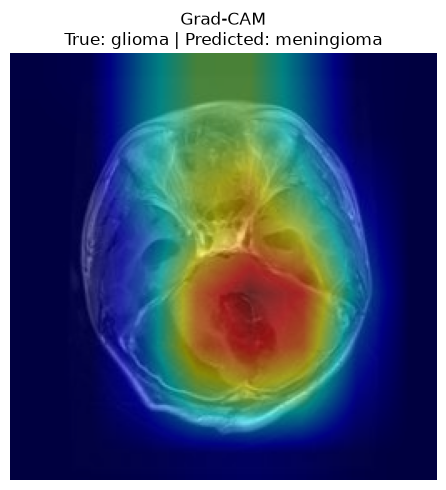

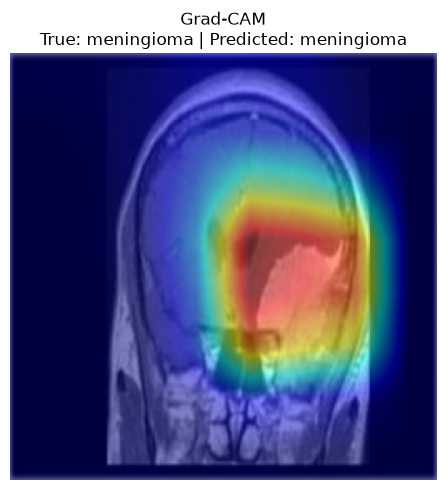

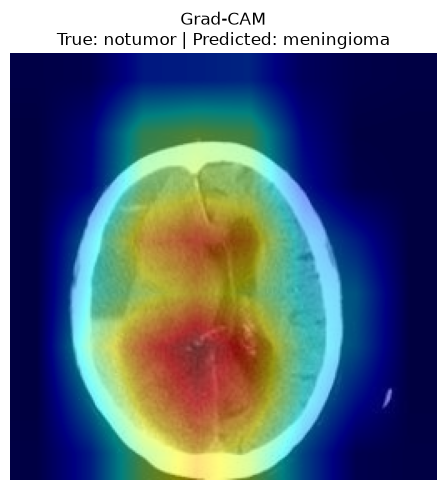

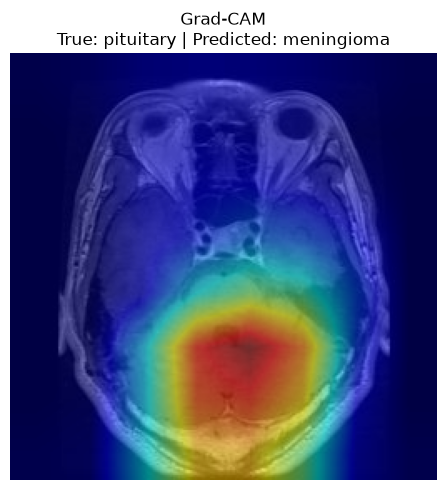

✅ Grad-CAM generation completed


In [29]:
import os
import torch
import torch.nn as nn
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

from torchvision import transforms
from torchvision.models import densenet121
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# --------------------------------
# DEVICE
# --------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# --------------------------------
# PATHS
# --------------------------------
model_path = r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\densenet121\densenet121_best_model.pth"
test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

if not os.path.exists(model_path):
    raise FileNotFoundError(f"Model not found:\n{model_path}")

# --------------------------------
# LOAD MODEL
# --------------------------------
model = densenet121(weights=None)

# Match saved classifier
model.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(1024, 4)
)

state_dict = torch.load(model_path, map_location=device)

model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print("✅ DenseNet121 loaded successfully")

# --------------------------------
# TARGET LAYER FOR GRAD-CAM
# --------------------------------
target_layer = model.features[-1]

# --------------------------------
# TRANSFORM (MATCH TRAINING)
# --------------------------------
input_size = 256

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

# --------------------------------
# CLASS NAMES
# --------------------------------
class_names = sorted([
    d for d in os.listdir(test_dir)
    if os.path.isdir(os.path.join(test_dir, d))
])

print("Classes:", class_names)

# --------------------------------
# GENERATE ONE GRAD-CAM PER CLASS
# --------------------------------
for class_name in class_names:

    class_path = os.path.join(test_dir, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if len(image_files) == 0:
        print(f"No images found in {class_name}")
        continue

    img_path = os.path.join(class_path, image_files[0])

    image = Image.open(img_path).convert("RGB")

    input_tensor = transform(image).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():
        output = model(input_tensor)
        pred_class = torch.argmax(output, dim=1).item()

    pred_class_name = class_names[pred_class]

    # Grad-CAM
    cam = GradCAM(
        model=model,
        target_layers=[target_layer]
    )

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(pred_class)]
    )[0]

    rgb_img = np.array(
        image.resize((input_size, input_size))
    ).astype(np.float32) / 255.0

    visualization = show_cam_on_image(
        rgb_img,
        grayscale_cam,
        use_rgb=True
    )

    # Display
    plt.figure(figsize=(8, 5))
    plt.imshow(visualization)
    plt.title(
        f"Grad-CAM\nTrue: {class_name} | Predicted: {pred_class_name}",
        fontsize=12
    )
    plt.axis("off")
    plt.tight_layout()
    plt.show()

print("✅ Grad-CAM generation completed")

In [34]:
import os
import torch
import torch.nn as nn
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

from torchvision import transforms
from torchvision.models import densenet121

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# -------------------------------
# 🔧 Config & Paths
# -------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

output_dir = r"C:\Users\Rashmitha R Nayak\Downloads\brainmri\gradcam_output_densenet"

os.makedirs(output_dir, exist_ok=True)

input_size = 256
num_classes = 4

# -------------------------------
# 🧠 Load DenseNet121 Model
# -------------------------------
model_path = r"C:\Users\Rashmitha R Nayak\Downloads\onlyclassification\densenet121\densenet121_best_model.pth"

if not os.path.exists(model_path):
    raise FileNotFoundError(f"Missing DenseNet checkpoint: {model_path}")

model = densenet121(weights=None)

# Match saved classifier structure
model.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(1024, 4)
)

state_dict = torch.load(model_path, map_location=device)

model.load_state_dict(state_dict)

model = model.to(device)
model.eval()

print("✅ DenseNet121 loaded successfully")

# -------------------------------
# 🎯 Grad-CAM Target Layer
# -------------------------------
target_layer = model.features[-1]

# -------------------------------
# 🔁 Transform
# Match training pipeline
# -------------------------------
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

# -------------------------------
# 🏷️ Class Names
# -------------------------------
class_names = sorted([
    d for d in os.listdir(test_dir)
    if os.path.isdir(os.path.join(test_dir, d))
])

print("🔍 Found classes:", class_names)

# -------------------------------
# 🔥 Grad-CAM Generation
# -------------------------------
image_count = 0

with GradCAM(model=model, target_layers=[target_layer]) as cam:

    for class_name in class_names:

        class_path = os.path.join(test_dir, class_name)

        image_files = [
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        if len(image_files) == 0:
            continue

        random.shuffle(image_files)

        for img_name in image_files[:3]:

            img_path = os.path.join(class_path, img_name)

            image = Image.open(img_path).convert("RGB")

            input_tensor = transform(image).unsqueeze(0).to(device)

            # Prediction
            with torch.no_grad():

                output = model(input_tensor)

                pred_class = torch.argmax(
                    output,
                    dim=1
                ).item()

                pred_name = class_names[pred_class]

            # Grad-CAM
            grayscale_cam = cam(
                input_tensor=input_tensor,
                targets=[
                    ClassifierOutputTarget(pred_class)
                ]
            )[0]

            rgb_img = (
                np.array(
                    image.resize((input_size, input_size))
                ).astype(np.float32) / 255.0
            )

            cam_overlay = show_cam_on_image(
                rgb_img,
                grayscale_cam,
                use_rgb=True
            )

            # Save
            class_output_dir = os.path.join(
                output_dir,
                class_name
            )

            os.makedirs(
                class_output_dir,
                exist_ok=True
            )

            save_path = os.path.join(
                class_output_dir,
                f"{img_name}_pred_{pred_name}_cam.jpg"
            )

            Image.fromarray(
                cam_overlay
            ).save(save_path)

            print(f"✅ Saved: {save_path}")

            image_count += 1

            if image_count >= 10:
                break

        if image_count >= 10:
            break

print(f"\n🎉 Generated {image_count} Grad-CAM images")
print(f"📂 Saved in: {output_dir}")

C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_9540\1182191595.py:46: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_path, map_location

✅ DenseNet121 loaded successfully
🔍 Found classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
✅ Saved: C:\Users\Rashmitha R Nayak\Downloads\brainmri\gradcam_output_densenet\glioma\Te-gl_0013.jpg_pred_meningioma_cam.jpg
✅ Saved: C:\Users\Rashmitha R Nayak\Downloads\brainmri\gradcam_output_densenet\glioma\Te-gl_0188.jpg_pred_glioma_cam.jpg
✅ Saved: C:\Users\Rashmitha R Nayak\Downloads\brainmri\gradcam_output_densenet\glioma\Te-gl_0166.jpg_pred_notumor_cam.jpg
✅ Saved: C:\Users\Rashmitha R Nayak\Downloads\brainmri\gradcam_output_densenet\meningioma\Te-me_0289.jpg_pred_meningioma_cam.jpg
✅ Saved: C:\Users\Rashmitha R Nayak\Downloads\brainmri\gradcam_output_densenet\meningioma\Te-me_0201.jpg_pred_meningioma_cam.jpg
✅ Saved: C:\Users\Rashmitha R Nayak\Downloads\brainmri\gradcam_output_densenet\meningioma\Te-me_0062.jpg_pred_meningioma_cam.jpg
✅ Saved: C:\Users\Rashmitha R Nayak\Downloads\brainmri\gradcam_output_densenet\notumor\Te-no_0234.jpg_pred_notumor_cam.jpg
✅ Saved: C:\Users\Rash

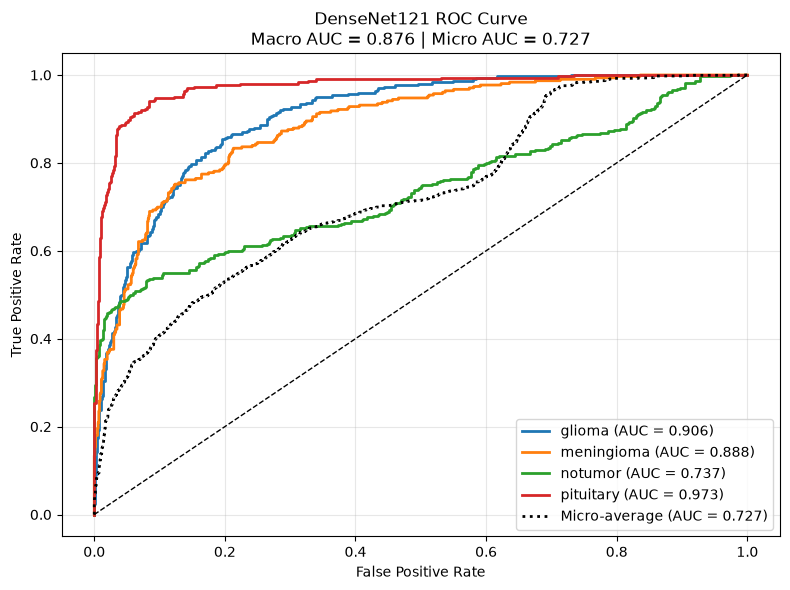


Per-Class AUC
glioma: 0.9060
meningioma: 0.8877
notumor: 0.7375
pituitary: 0.9729

Macro AUC : 0.8760
Micro AUC : 0.7272


In [35]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# ----------------------------------------
# ROC-AUC Evaluation
# ----------------------------------------

model.eval()

all_probs = []
all_labels = []

with torch.no_grad():

    for class_idx, class_name in enumerate(class_names):

        class_path = os.path.join(test_dir, class_name)

        image_files = [
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        for img_name in image_files:

            img_path = os.path.join(class_path, img_name)

            image = Image.open(img_path).convert("RGB")

            input_tensor = transform(image).unsqueeze(0).to(device)

            outputs = model(input_tensor)

            probs = torch.softmax(
                outputs,
                dim=1
            )[0].cpu().numpy()

            all_probs.append(probs)
            all_labels.append(class_idx)

# ----------------------------------------
# Convert to numpy
# ----------------------------------------

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

num_classes = len(class_names)

y_true = label_binarize(
    all_labels,
    classes=list(range(num_classes))
)

# ----------------------------------------
# Compute ROC Curves
# ----------------------------------------

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):

    fpr[i], tpr[i], _ = roc_curve(
        y_true[:, i],
        all_probs[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

# Macro AUC
macro_auc = roc_auc_score(
    y_true,
    all_probs,
    average="macro",
    multi_class="ovr"
)

# Micro AUC
fpr_micro, tpr_micro, _ = roc_curve(
    y_true.ravel(),
    all_probs.ravel()
)

micro_auc = auc(
    fpr_micro,
    tpr_micro
)

# ----------------------------------------
# Plot
# ----------------------------------------

plt.figure(figsize=(8, 6))

colors = [
    "tab:blue",
    "tab:orange",
    "tab:green",
    "tab:red"
]

for i, class_name in enumerate(class_names):

    plt.plot(
        fpr[i],
        tpr[i],
        lw=2,
        color=colors[i],
        label=f"{class_name} (AUC = {roc_auc[i]:.3f})"
    )

plt.plot(
    fpr_micro,
    tpr_micro,
    color="black",
    linestyle=":",
    lw=2,
    label=f"Micro-average (AUC = {micro_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    lw=1
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"DenseNet121 ROC Curve\n"
    f"Macro AUC = {macro_auc:.3f} | "
    f"Micro AUC = {micro_auc:.3f}"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "DenseNet121_ROC_AUC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ----------------------------------------
# Print Results
# ----------------------------------------

print("\nPer-Class AUC")

for i, class_name in enumerate(class_names):
    print(
        f"{class_name}: {roc_auc[i]:.4f}"
    )

print(f"\nMacro AUC : {macro_auc:.4f}")
print(f"Micro AUC : {micro_auc:.4f}")

In [32]:
print(class_names)

['glioma', 'meningioma', 'notumor', 'pituitary']


In [33]:
print(class_names)
print(train_dataset.classes)

['glioma', 'meningioma', 'notumor', 'pituitary']
['glioma', 'meningioma', 'notumor', 'pituitary']


Using device: cuda

Epoch 1/5


→ Train Accuracy: 91.47%
✅ Saved Best Model

Epoch 2/5


→ Train Accuracy: 96.32%
✅ Saved Best Model

Epoch 3/5


→ Train Accuracy: 96.87%
✅ Saved Best Model

Epoch 4/5


→ Train Accuracy: 98.13%
✅ Saved Best Model

Epoch 5/5


→ Train Accuracy: 98.79%
✅ Saved Best Model



🢾 Classification Report:
              precision    recall  f1-score   support

      glioma       1.00      1.00      1.00       300
  meningioma       0.99      0.98      0.99       306
     notumor       0.99      1.00      0.99       405
   pituitary       1.00      1.00      1.00       300

    accuracy                           0.99      1311
   macro avg       0.99      0.99      0.99      1311
weighted avg       0.99      0.99      0.99      1311



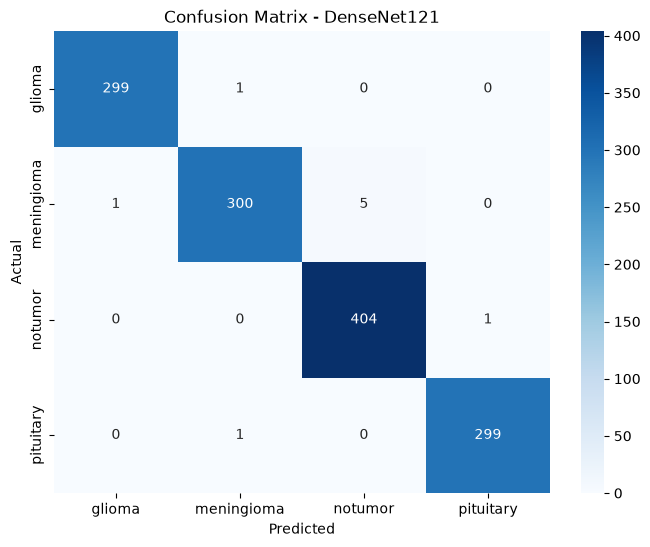

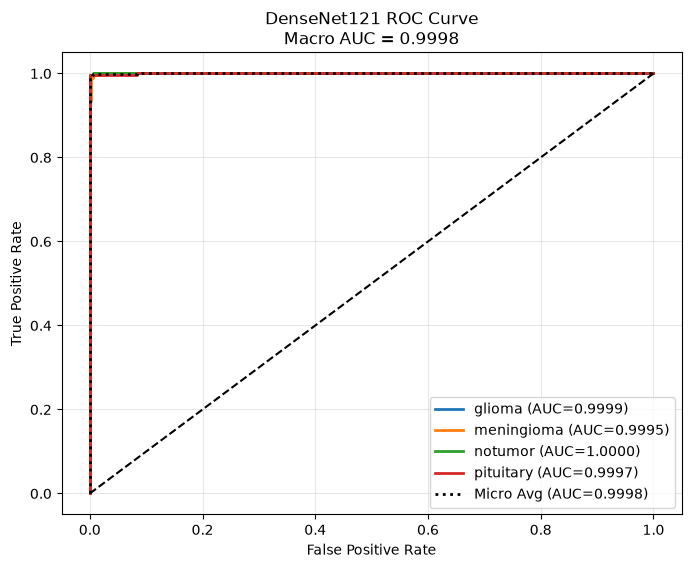


Per-Class AUC
glioma: 0.9999
meningioma: 0.9995
notumor: 1.0000
pituitary: 0.9997

Macro AUC : 0.9998
Micro AUC : 0.9998


In [37]:
#  Final Training + Testing for DenseNet121 (Without Cross-Validation)

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import densenet121, DenseNet121_Weights
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
import json
from tqdm import tqdm

#  Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

#  Dataset paths (update if different)
train_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Training_256x256"
test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

#  Transforms
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

#  Load Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)

#  DataLoaders
batch_size = 32
full_train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

#  Define Model (DenseNet121)
import torch.nn as nn
import torch.optim as optim

def create_model(lr, wd):
    weights = DenseNet121_Weights.DEFAULT
    model = densenet121(weights=weights)
    model.classifier = nn.Linear(model.classifier.in_features, len(train_dataset.classes))
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
    criterion = nn.CrossEntropyLoss()
    return model, optimizer, scheduler, criterion

#  Best Hyperparameters (replace with your best found)
best_config = {
    'learning_rate': 0.0005,
    'weight_decay': 1e-4
}
EPOCHS = 5

#  Create Model
model, optimizer, scheduler, criterion = create_model(best_config['learning_rate'], best_config['weight_decay'])
model = model.to(device)

#  AMP
scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))
train_accuracies, train_losses = [], []
best_train_acc = 0

#  Training
for epoch in range(EPOCHS):
    print(f"\n\033[95mEpoch {epoch+1}/{EPOCHS}\033[0m")
    model.train()
    correct, total, epoch_loss = 0, 0, 0.0

    for imgs, labels in tqdm(full_train_loader, desc=f"Epoch {epoch+1} [Train]", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            outputs = model(imgs)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        epoch_loss += loss.item()

    train_acc = 100 * correct / total
    train_accuracies.append(train_acc)
    train_losses.append(epoch_loss / len(full_train_loader))
    print(f"→ Train Accuracy: {train_acc:.2f}%")
    if train_acc > best_train_acc:
        best_train_acc = train_acc

    torch.save(
        model.state_dict(),
        "densenet121_retrained_best.pth"
    )

    print("✅ Saved Best Model")
    scheduler.step()

#  Testing
model.eval()
correct, total = 0, 0
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Testing", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            outputs = model(imgs)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

final_test_acc = float(100 * correct / total)
torch.save(
    model.state_dict(),
    "densenet121_final.pth"
)

#  Classification Report
print("\n\U0001F8BE Classification Report:")
print(classification_report(all_labels, all_preds, target_names=train_dataset.classes))

#  Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_dataset.classes,
            yticklabels=train_dataset.classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - DenseNet121")
plt.show()

# -------------------------------
# ROC-AUC
# -------------------------------

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
import numpy as np

all_probs = []

model.eval()

with torch.no_grad():

    for imgs, labels in test_loader:

        imgs = imgs.to(device)

        outputs = model(imgs)

        probs = torch.softmax(
            outputs,
            dim=1
        )

        all_probs.extend(
            probs.cpu().numpy()
        )

all_probs = np.array(all_probs)
all_labels_np = np.array(all_labels)

num_classes = len(train_dataset.classes)

y_true = label_binarize(
    all_labels_np,
    classes=list(range(num_classes))
)

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):

    fpr[i], tpr[i], _ = roc_curve(
        y_true[:, i],
        all_probs[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

macro_auc = roc_auc_score(
    y_true,
    all_probs,
    average="macro",
    multi_class="ovr"
)

fpr_micro, tpr_micro, _ = roc_curve(
    y_true.ravel(),
    all_probs.ravel()
)

micro_auc = auc(
    fpr_micro,
    tpr_micro
)

plt.figure(figsize=(8,6))

for i, cls in enumerate(train_dataset.classes):

    plt.plot(
        fpr[i],
        tpr[i],
        lw=2,
        label=f"{cls} (AUC={roc_auc[i]:.4f})"
    )

plt.plot(
    fpr_micro,
    tpr_micro,
    'k:',
    lw=2,
    label=f"Micro Avg (AUC={micro_auc:.4f})"
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"DenseNet121 ROC Curve\nMacro AUC = {macro_auc:.4f}"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

print("\nPer-Class AUC")
for i, cls in enumerate(train_dataset.classes):
    print(f"{cls}: {roc_auc[i]:.4f}")

print(f"\nMacro AUC : {macro_auc:.4f}")
print(f"Micro AUC : {micro_auc:.4f}")

#  Save Metrics
params = float(sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6)
precision = float(precision_score(all_labels, all_preds, average='macro'))
recall = float(recall_score(all_labels, all_preds, average='macro'))
f1 = float(f1_score(all_labels, all_preds, average='macro'))

metrics = {
    "mode": "without_cv",
    "accuracy": round(float(final_test_acc), 2),
    "precision": round(precision * 100, 2),
    "recall": round(recall * 100, 2),
    "f1_score": round(f1 * 100, 2),
    "parameters_million": round(params, 2)
}

with open("metrics_densenet121_without_cv.json", "w") as f:
    json.dump(metrics, f, indent=4)


In [3]:
import torch
import torch.nn as nn
import numpy as np

from torchvision import datasets, transforms
from torchvision.models import densenet121, DenseNet121_Weights
from torch.utils.data import DataLoader
from tqdm import tqdm

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

test_dir = r"C:\Users\Rashmitha R Nayak\Downloads\archive\Testing_256x256"

test_transform = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.ToTensor()
])

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(test_dataset.classes)

Using: cuda
['glioma', 'meningioma', 'notumor', 'pituitary']


In [5]:
model = densenet121(weights=None)

model.classifier = nn.Linear(
    model.classifier.in_features,
    len(test_dataset.classes)
)

model.load_state_dict(
    torch.load(
        r"C:\Users\Rashmitha R Nayak\OneDrive\Desktop\Brain_Tumor\densenet\densenet121_retrained_best.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("DenseNet121 loaded successfully!")

C:\Users\Rashmitha R Nayak\AppData\Local\Temp\ipykernel_12096\246543458.py:9: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


DenseNet121 loaded successfully!


In [6]:
all_preds = []
all_labels = []

with torch.no_grad():

    for imgs, labels in tqdm(test_loader):

        imgs = imgs.to(device)

        outputs = model(imgs)

        preds = outputs.argmax(dim=1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

print("Prediction complete!")

100%|██████████| 41/41 [00:30<00:00,  1.36it/s]

Prediction complete!


In [7]:
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

np.save("dense_preds.npy", all_preds)
np.save("true_labels.npy", all_labels)

print("Saved!")

print(all_preds.shape)
print(all_labels.shape)

Saved!
(1311,)
(1311,)
